# Analysis of experimental data

This notebook documents analysis of experimental data resulting from developed pitch pipelines. This document is focused on analysis and findings. For complete analysis code see ./pitch_analysis.py

## 1. Datasets used

- [ChoraleBricks](https://zenodo.org/records/15081741)

## 2. Metrics

### GPE (Gross Pitch Error)
The proportion of (voiced) frames for which estimated f0 was substantially different from the reference data

### MAE (Mean Absolute Error)
The average absolute error across all frames

In [2]:
from pathlib import Path
import pandas as pd
import pitch_analysis
import os
import re

Here we load the raw data from experiments conducted in kotlin, including timestamped predictions per dataset per file, but without labelled f0 data.

In [7]:
experiment_data_folder = Path.cwd().parent.parent.parent / "experimental_data"
dataPath = experiment_data_folder / "window_size"
resultsFiles = [path for path in dataPath.iterdir() if path.is_file() and "windowSize" in path.name]

summary_export_name = Path.cwd() / "results" / "effect_of_window_size.csv"

# 3. Window Size
In this section we investigate the impact of window size, that is to say the number of audio samples included in each estimation window. This can be expected to impact accuracy as a larger window means more information is available to the algorithm, however the impact is likely to be non-monotonic as too large a window is likely to include pitch transitions, reducing the specificity of the estimate. We would therefore expect to see an inverted U-shaped relationship where accuracy increases with window up to some threshold beyond which increasing window size has an adverse effect on accuracy.

The relationship between window size and processing time is less intuitive and depends on algorithm and implementation factors, but in general it's hypothesized that window size will be positively correlated with processing time as larger windows will be more computationally expensive. 

## 3.1 data processing
Here we conduct the following steps on the raw experimental data:

1. For each audio file, find the corresponding labelled data
2. Align the estimated timestamps with the labelled data
3. Based on aligned timestamps, compare labelled f0 vs predicted f0 across dataset to calculate metrics

In [4]:
def process_window_results(file: Path):

    # get window size from filename
    windowSize = int(re.search(r"(\d+)\.csv$", file.name).group(1))
    # process data
    file_data = pitch_analysis.PitchExperimentData(file)
    processed_data = file_data.process()
    # add window size column
    processed_data.insert(1, "windowSize", windowSize)
    # add instrument column
    processed_data["instrument"] = (
        processed_data["track"]
            .str
            .split("_")
            .str[-1]
            .str
            .removesuffix(".wav")
        )
    summary = (
        processed_data.groupby(["windowSize","estimator", "dataset"], as_index=False)
        .agg({
            "MAE": "mean",
            "GPE": "mean",
            "processing_time_file": "mean"
        })
    )
    return summary

processed_data = [process_window_results(file) for file in resultsFiles]


Aggregate results from different window sizes into a combined dataframe

In [10]:
combined_results = pd.concat(processed_data, ignore_index=True)
combined_results.sort_values(
    by=["estimator", "windowSize"],
    ascending=[True,True]
)
combined_results.to_csv(summary_export_name,index=False)

In [ ]:
# read results from csv to prevent having to recalculate everything
window_data = pd.read_csv(summary_export_name)

window_data = window_data.sort_values(
    by=["estimator", "windowSize"],
    ascending=[True,True]
)
window_data

,windowSize,estimator,dataset,MAE,GPE,processing_time_file
8,256,DynamicWaveletEstimator,ChoraleBricks,677.627177,36.666859,273.404145
12,512,DynamicWaveletEstimator,ChoraleBricks,281.847796,19.175668,276.658031
0,1024,DynamicWaveletEstimator,ChoraleBricks,108.377856,10.694251,245.461140
4,2048,DynamicWaveletEstimator,ChoraleBricks,87.928717,10.806926,301.689119
9,256,FastYinEstimator,ChoraleBricks,753.486631,51.211691,121.160622
13,512,FastYinEstimator,ChoraleBricks,174.145870,13.831976,148.093264
1,1024,FastYinEstimator,ChoraleBricks,40.023509,5.818493,123.797927
5,2048,FastYinEstimator,ChoraleBricks,44.172143,7.624308,164.875648
10,256,McLeodEstimator,ChoraleBricks,269.904585,22.905557,460.264249
14,512,McLeodEstimator,ChoraleBricks,90.133400,8.609504,909.181347


## 3.2 Visualizing effect of window size

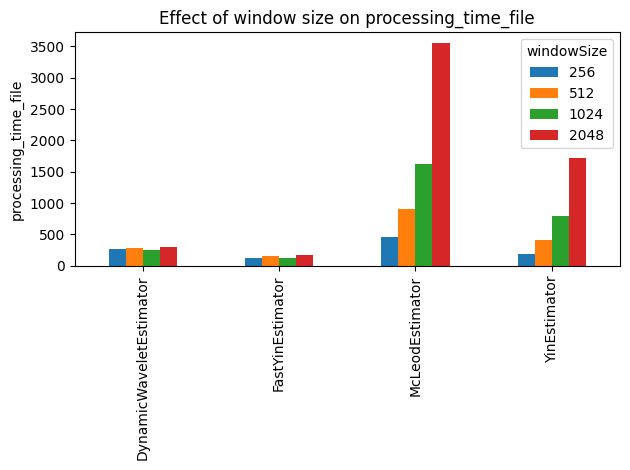

In [ ]:
import matplotlib.pyplot as plt

# here we define a custom function to show the effect of window size on different metrics

def window_size_chart(
    df: pd.DataFrame,
    metric: str,
):
    chart_data = df[["windowSize","estimator",metric]].pivot(
        index="estimator",
        columns="windowSize",
        values=metric
    )
    ax = chart_data.plot(
        kind="bar"
        )
    ax.set_title(f"Effect of window size on {metric}")
    ax.set_xlabel(None)
    ax.set_ylabel(metric)
    plt.tight_layout()
    plt.show()


### Chart 1 - Effect of window size on MAE (mean absolute error)

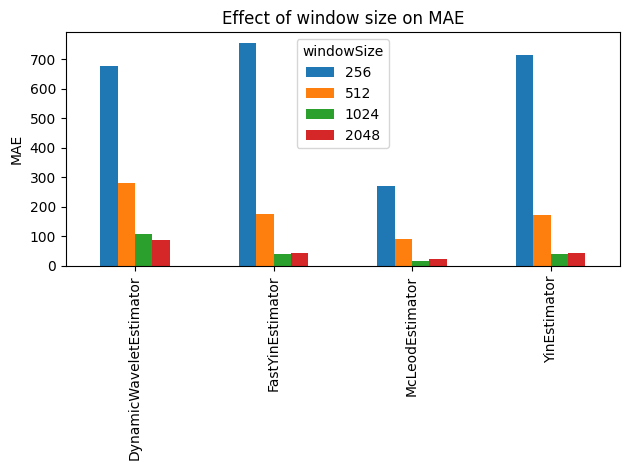

In [57]:
window_size_chart(window_data,"MAE")

### Chart 2 - Effect of window size on Gross Pitch Error (GPE)

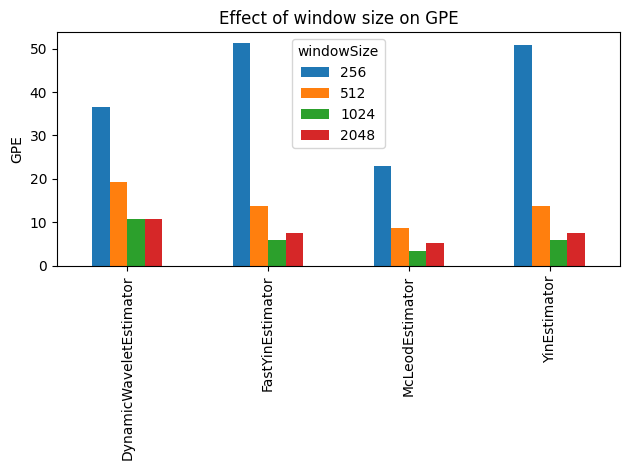

In [58]:
window_size_chart(window_data,"GPE")

### Chart 3 - Effect of window size on processing time

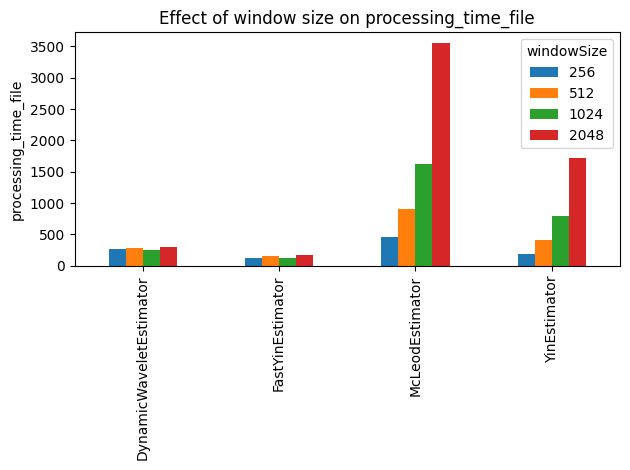

In [59]:
window_size_chart(window_data,"processing_time_file")

## 3.3 Conclusions regarding effect of window size
These analyses largely affirm the expected relationships between window size and accuracy, with increasing window size generally having a positive impact on accuracy up to size=1024, and larger windows generally leading to increased processing time. Based on these results 1024 was chosen as the window size for the application as it appears to be optimal for accuracy, with an acceptable tradeoff on processing time. This can be revisited if processing latency is shown to be an issue during testing and evaluation.

# 4. Comparing pitch algorithms
In this section we directly compare the performance of the pitch estimators tested, using the window size selected in section 3.

In [ ]:
df = pd.read_csv(Path.cwd() / "data" / "ChoraleBricks__windowSize1024.csv")
df.head()